In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df  = pd.read_csv("/content/sample_data/california_housing_test.csv")

In [ ]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-122.05,37.37,27.0,3885.0,661.0,1537.0,606.0,6.6085,344700.0
1,-118.30,34.26,43.0,1510.0,310.0,809.0,277.0,3.5990,176500.0
2,-117.81,33.78,27.0,3589.0,507.0,1484.0,495.0,5.7934,270500.0
3,-118.36,33.82,28.0,67.0,15.0,49.0,11.0,6.1359,330000.0
4,-119.67,36.33,19.0,1241.0,244.0,850.0,237.0,2.9375,81700.0


In [ ]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0


In [ ]:
df.shape

(3000, 9)

In [ ]:
x = df.drop('median_house_value', axis = 1 )
y = df['median_house_value']

6 Aug


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test ,Y_train , Y_test = train_test_split(x,y,test_size=0.2,random_state=0)

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(X_train, Y_train)

LinearRegression()

Predictions


In [ ]:
X_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
311,-121.77,37.68,41.0,1501.0,299.0,629.0,288.0,4.6806
1025,-118.24,33.91,37.0,1607.0,377.0,1526.0,375.0,1.7158
1587,-118.22,33.96,42.0,1380.0,331.0,1290.0,288.0,2.8000
2941,-121.50,38.57,41.0,1124.0,344.0,807.0,316.0,1.4712
2980,-119.76,36.79,32.0,2463.0,468.0,1261.0,486.0,3.3281
...,...,...,...,...,...,...,...,...
913,-123.85,39.39,23.0,4671.0,912.0,2095.0,857.0,3.1840
1431,-117.84,33.89,24.0,3935.0,625.0,1912.0,593.0,5.7951
654,-117.95,33.93,37.0,2633.0,630.0,1904.0,630.0,2.6123
476,-122.15,37.47,37.0,1844.0,382.0,1634.0,417.0,2.7993


In [ ]:
Y_test

,median_house_value
311,209400.0
1025,94300.0
1587,161800.0
2941,94600.0
2980,75100.0
...,...
913,140500.0
1431,226900.0
654,161300.0
476,145500.0


In [ ]:
lr.predict(X_test.iloc[[0]])

array([264574.51192722])

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error , r2_score


In [ ]:
y_pred = lr.predict(X_test)

In [ ]:
print("MAE:",mean_absolute_error(Y_test,y_pred) )
print("MSE:",mean_squared_error(Y_test, y_pred) )
print("RMSE:",root_mean_squared_error(Y_test, y_pred))
print("R2:",r2_score(Y_test, y_pred))

MAE: 52237.15050209894
MSE: 4917020012.473105
RMSE: 70121.4661317995
R2: 0.6358812265513638


8 Aug

Polynomial Regression


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model  import LinearRegression
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df  = pd.read_csv("/content/drive/MyDrive/Admission_Predict.xlsx - Admission_Predict.csv")

In [ ]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,1
1,2,324,107,4,4.0,4.5,8.87,1,1
2,3,316,104,3,3.0,3.5,8.00,1,0
3,4,322,110,3,3.5,2.5,8.67,1,1
4,5,314,103,2,2.0,3.0,8.21,0,0


In [ ]:
X = df.drop('Chance of Admit', axis = 1)
y = df['Chance of Admit']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=0)

In [ ]:
poly  = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly  = poly.transform(X_test)

In [ ]:
model = LinearRegression()
model.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(X_test_poly)

In [ ]:
# 8. Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


# 9. Coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

MAE : 0.26149454860053967
MSE : 0.1141824600547654
RMSE: 0.33790895231521373
R2 Score: 0.524239749771811
Intercept: -37.61314037311556
Coefficients: [ 4.53668664e-10  3.39145476e-03  3.92881295e-01 -1.77441013e-01
  1.57701636e-01 -4.69207750e-01 -4.25109254e-02 -3.79260530e+00
 -5.45316111e-02 -1.82383079e-07 -1.54667094e-05 -2.94186942e-06
  4.80482789e-05  4.27975335e-04 -6.99370445e-04  3.45381463e-04
  4.63043804e-04 -8.34289134e-04  5.94137133e-04  2.97104976e-03
  3.91075840e-04  8.16923308e-03  4.81848435e-03 -9.63902424e-03
 -1.03636144e-04 -8.06666660e-04 -6.27174183e-03 -1.77308766e-02
  1.05464699e-02  2.30526891e-02  1.79194076e-02 -1.06149976e-02
  9.18101444e-02 -1.58136092e-01 -1.78160188e-02 -2.32216032e-03
 -7.30665149e-03  1.26482245e-01 -3.50557607e-02  3.21240795e-02
 -1.04078704e-01 -8.24960958e-02  9.96173037e-02  1.36471150e-01
 -5.45316113e-02]


Ridge Regualization


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler


In [ ]:
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1,1
1,2,324,107,4,4.0,4.5,8.87,1,1
2,3,316,104,3,3.0,3.5,8.00,1,0
3,4,322,110,3,3.5,2.5,8.67,1,1
4,5,314,103,2,2.0,3.0,8.21,0,0


In [ ]:
scaler = StandardScaler()

In [ ]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
alpha = [0,0.1,0.01,0.02]
coeff = []
pred = []
for i in alpha:
  model = Ridge(alpha = i )
  model.fit(X_train,y_train)
  coeff.append(model.coef_.tolist())
  y_pred = model.predict(X_test)
  pred.append(y_pred)
  print("MAE:",mean_absolute_error(y_test,y_pred) )

MAE: 32.16784905601207
MAE: 32.192160571048284
MAE: 32.17028713394622
MAE: 32.17272366952884


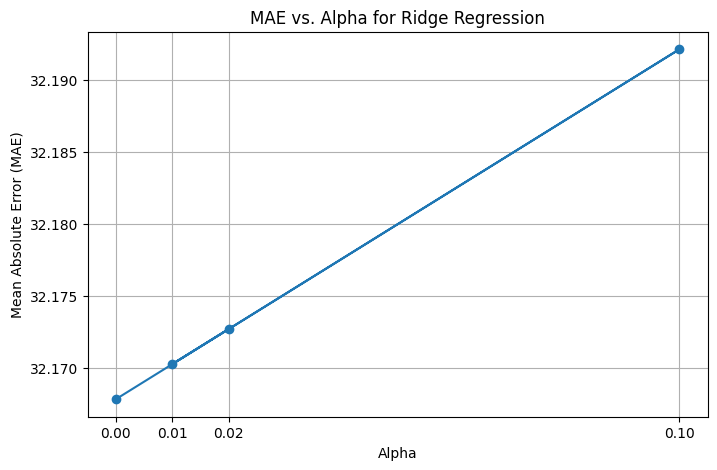

In [ ]:
import matplotlib.pyplot as plt

alpha_values = [0, 0.1, 0.01, 0.02]
mae_results = [
    32.16784905601207,
    32.192160571048284,
    32.17028713394622,
    32.17272366952884
]

plt.figure(figsize=(8, 5))
plt.plot(alpha_values, mae_results, marker='o')
plt.title('MAE vs. Alpha for Ridge Regression')
plt.xlabel('Alpha')
plt.ylabel('Mean Absolute Error (MAE)')
plt.grid(True)
plt.xticks(alpha_values)
plt.show()

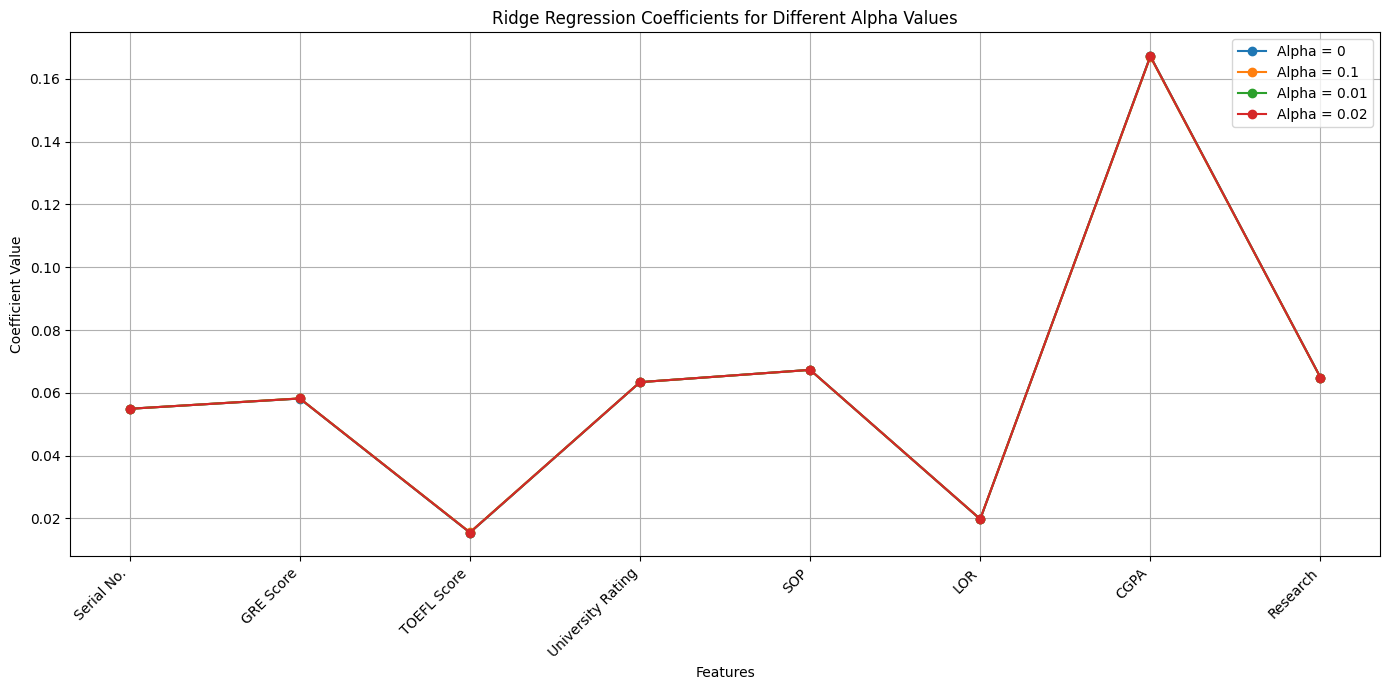

In [ ]:
import matplotlib.pyplot as plt

# Get feature names from the original X DataFrame
# X was defined as df.drop('Chance of Admit', axis=1)
feature_names = X.columns.tolist()

plt.figure(figsize=(14, 7))

# Plot coefficients for each alpha value from the 'coeff' list
# 'coeff' contains lists of coefficients for alpha = [0, 0.1, 0.01, 0.02]
for i, alpha_val in enumerate(alpha):
    plt.plot(feature_names, coeff[i], marker='o', label=f'Alpha = {alpha_val}')

plt.title('Ridge Regression Coefficients for Different Alpha Values')
plt.xlabel('Features')
plt.ylabel('Coefficient Value')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.legend()
plt.grid(True)
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

### Interpretation of Ridge Regression Coefficients

The plot above displays the coefficients learned by the Ridge regression model for each feature, across different `alpha` (regularization strength) values.

*   **`alpha = 0` (Linear Regression baseline):** This line represents the coefficients when no L2 regularization is applied, which is equivalent to standard Linear Regression on the scaled features. These coefficients can often be larger in magnitude.

*   **`alpha > 0` (Ridge Regression):** As `alpha` increases, the regularization strength increases. You can observe that the coefficients for `alpha = 0.01`, `alpha = 0.02`, and `alpha = 0.1` are slightly *shrunk* towards zero compared to the `alpha = 0` (linear regression) coefficients. This shrinkage helps to prevent overfitting by penalizing large coefficient values. For instance, notice how the coefficients for 'Serial No.' and 'Research' are very close to zero for all alpha values, indicating they might have less impact on the prediction in this scaled context.